# 05 · The graph

This notebook builds the data for the interactive page (`docs/index.html`). The main idea of the page is that an article's theme (its cluster from notebook 04) and its closeness to the war (its similarity to the seed from notebook 02) are two different things.

The page has two views and animates between them:

| View | Position means |
|---|---|
| Radial | angle = theme (one wedge per cluster), distance from the center = rank in similarity to the seed |
| Network | similar articles are pulled together (the force layout from notebook 04) |

Both layouts are computed here in Python and exported with the article details to `docs/data.js`, so the browser only animates between saved positions. The layout code is in `src/layout.py`.

In [1]:
import base64
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clustering
import layout
import similarity

SEED = "Hundred Years' War"
K = 10  # neighbors per article, as in notebook 04

data = ROOT / "data" / "processed"
clusters = pd.read_parquet(data / "clusters.parquet").set_index("title")
seed_similarity = pd.read_parquet(data / "seed_similarity.parquet").set_index("title")
articles = pd.read_parquet(data / "articles.parquet").set_index("title")
types = pd.read_parquet(data / "article_types.parquet").set_index("title")  # from notebook 03: labeled or predicted
pairs = pd.read_parquet(data / "pairs.parquet")
pairs = pairs[(pairs["a"] != SEED) & (pairs["b"] != SEED)]
mw = similarity.from_pairs(pairs, "milne_witten")
inlink = similarity.from_pairs(pairs, "inlink")
outlink = similarity.from_pairs(pairs, "outlink")
titles = mw.index
labels = clusters.loc[titles, "cluster"]
names = clusters.groupby("cluster")["cluster_name"].first()
seed_rank = seed_similarity.loc[titles, "milne_witten_rank"]
graph = clustering.knn_graph(mw, K)
print(f"{len(titles)} articles in {labels.nunique()} clusters | {graph.number_of_edges():,} edges")

# Closeness colors: one blue ramp, dark = most similar to the seed.
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
closeness_cmap = LinearSegmentedColormap.from_list("closeness", BLUES[::-1])

788 articles in 12 clusters | 6,243 edges


## 1. Network layout

The same force layout as in notebook 04, colored by closeness to the seed (darker = closer). The two don't line up: close and distant articles are mixed together in most regions.

In the raw layout the themes overlap a lot. That's accurate (silhouette 0.21 on the similarities) but hard to read, so I move each theme as a block away from the center (`layout.spread_clusters`). Articles keep their positions within a theme and only the gaps between themes get bigger. This makes the themes look more separate than they really are (the 2-D silhouette printed below roughly triples), so the page points that out in the network view.

2-D silhouette by theme: 0.17 as laid out, 0.47 after spreading


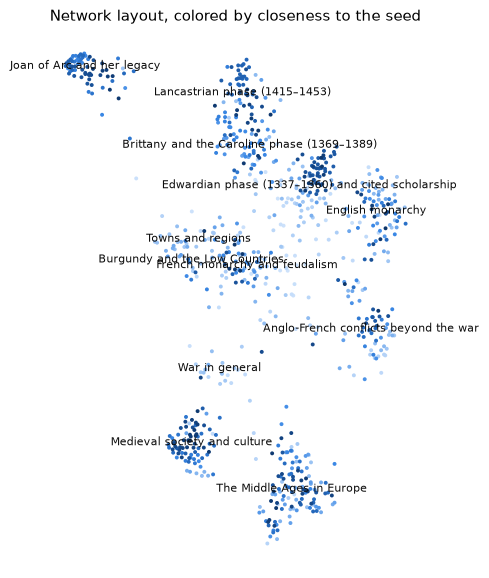

In [2]:
force = layout.network_layout(graph, seed=0).loc[titles]
# Pull the themes apart for readability: each theme moves as a block, keeping its shape.
SPREAD = 1.0
network = layout.spread_clusters(force, labels, SPREAD)
print(f"2-D silhouette by theme: {silhouette_score(force, labels):.2f} as laid out, "
      f"{silhouette_score(network, labels):.2f} after spreading")

def preview(xy, ax, title):
    order = np.argsort(-seed_rank.to_numpy())  # draw the closest articles last, on top
    ax.scatter(xy["x"].to_numpy()[order], xy["y"].to_numpy()[order], s=8, linewidths=0,
               c=seed_rank.to_numpy()[order], cmap=closeness_cmap)
    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(7, 7))
preview(network, ax, "Network layout, colored by closeness to the seed")
for c, name in names.items():
    x, y = network[labels == c].median()
    ax.annotate(name, (x, y), ha="center", fontsize=8, color="#0b0b0b")

## 2. Radial layout

The seed sits at the center and each cluster gets a wedge sized by its number of articles.

- Wedge order: similar themes sit next to each other. The similarity between two clusters is the mean Milne–Witten similarity between their articles, and the order comes from hierarchical clustering of the clusters with optimal leaf ordering, so neighboring wedges are as similar as possible.
- Distance from the center: √(rank / 788), where rank 1 is the article most similar to the seed. The square root means every ring of equal area holds the same number of articles, so the center isn't crowded and the edge isn't empty.
- Within a wedge, articles are spaced by the golden angle so articles with neighboring ranks don't land on top of each other.

In [3]:
order = layout.cluster_order(mw, labels)
radial, wedges = layout.radial_layout(labels, seed_rank, order)

own = labels.to_numpy()
between = pd.DataFrame(
    [[mw.to_numpy()[np.ix_(own == a, own == b)].mean() for b in order] for a in order],
    index=names[order], columns=names[order],
)
between.round(2)

cluster_name,War in general,Medieval society and culture,The Middle Ages in Europe,Edwardian phase (1337–1360) and cited scholarship,English monarchy,Burgundy and the Low Countries,French monarchy and feudalism,Brittany and the Caroline phase (1369–1389),Lancastrian phase (1415–1453),Joan of Arc and her legacy,Anglo-French conflicts beyond the war,Towns and regions
cluster_name,,,,,,,,,,,,
War in general,0.68,0.40,0.41,0.33,0.30,0.33,0.29,0.35,0.38,0.27,0.43,0.25
Medieval society and culture,0.40,0.89,0.73,0.42,0.48,0.50,0.49,0.48,0.45,0.37,0.43,0.36
The Middle Ages in Europe,0.41,0.73,0.78,0.33,0.39,0.43,0.43,0.36,0.33,0.27,0.47,0.36
Edwardian phase (1337–1360) and cited scholarship,0.33,0.42,0.33,0.56,0.50,0.46,0.48,0.61,0.61,0.45,0.45,0.42
English monarchy,0.30,0.48,0.39,0.50,0.70,0.49,0.55,0.59,0.60,0.39,0.48,0.41
Burgundy and the Low Countries,0.33,0.50,0.43,0.46,0.49,0.81,0.61,0.59,0.63,0.46,0.50,0.45
French monarchy and feudalism,0.29,0.49,0.43,0.48,0.55,0.61,0.75,0.61,0.61,0.48,0.50,0.49
Brittany and the Caroline phase (1369–1389),0.35,0.48,0.36,0.61,0.59,0.59,0.61,0.81,0.76,0.55,0.56,0.49
Lancastrian phase (1415–1453),0.38,0.45,0.33,0.61,0.60,0.63,0.61,0.76,0.93,0.84,0.57,0.52


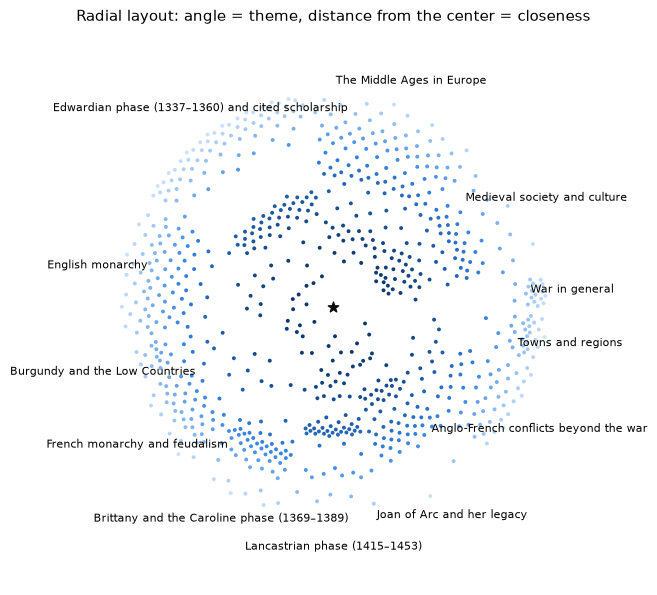

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
preview(radial, ax, "Radial layout: angle = theme, distance from the center = closeness")
ax.scatter([0], [0], s=60, marker="*", color="#0b0b0b")
for c, (start, end) in wedges.items():
    mid = (start + end) / 2
    ax.annotate(names[c], (1.12 * np.cos(mid), 1.12 * np.sin(mid)), ha="center", va="center", fontsize=8)
ax.set(xlim=(-1.45, 1.45), ylim=(-1.3, 1.3));

Wedges with articles near the center are the themes closest to the war, like the Lancastrian phase and Joan of Arc. Wedges with articles near the edge are farther away, like war in general and towns and regions, which matches the cluster profiles in notebook 04.

## 3. Export

Each article also carries the fields the page filters on and shows in its infobox: its type (from notebook 03), length, the share of its links that go to other articles in the set, and whether it links back to the seed. The export also includes the three scores for every pair of articles (310,078 pairs), so the related-articles table can rank any filtered subset. The pair scores are packed as 2-byte integers to keep the file small.

Everything goes into `docs/data.js` as one JavaScript object (`window.GRAPH`) rather than a JSON file. Browsers block `fetch` on local files, but a script tag still works when you just double-click `index.html`.

In [5]:
def cut(text, limit=400):
    # Shorten to whole words, ending with an ellipsis.
    text = (text or "").strip()
    return text if len(text) <= limit else text[:limit].rsplit(" ", 1)[0] + "…"

position_of = {t: i for i, t in enumerate(titles)}
round3 = lambda v: round(float(v), 3)

nodes = []
for i, t in enumerate(titles):
    s = seed_similarity.loc[t]
    nodes.append({
        "title": t,
        "cluster": int(labels[t]),
        "shortdesc": articles.at[t, "shortdesc"] or "",
        "paragraph": cut(articles.at[t, "first_paragraph"]),
        "rank": int(s["milne_witten_rank"]),
        "milne_witten": round3(s["milne_witten"]),
        "outlink": round3(s["outlink"]),
        "inlink": round3(s["inlink"]),
        "outside_share": round3(clusters.at[t, "outside_share"]),
        "radial": [round3(radial.at[t, "x"]), round3(radial.at[t, "y"])],
        "network": [round3(network.at[t, "x"]), round3(network.at[t, "y"])],
        "word_count": int(articles.at[t, "word_count"]),
        "pct_out": round(float(articles.at[t, "pct_out_degree"]), 6),  # share of its links that stay in the set; 6 decimals so articles don't shift across bin edges
        "links_to_seed": bool(articles.at[t, "links_to_seed"]),
        "type": types.at[t, "type"],
        "type_predicted": bool(types.at[t, "type_source"] == "predicted"),
    })

edges = [[position_of[u], position_of[v], round3(w)] for u, v, w in graph.edges(data="weight")]

cluster_info = []
for c in order:
    start, end = wedges[c]
    members = network[labels == c]
    cluster_info.append({
        "id": int(c),
        "name": names[c],
        "size": int((labels == c).sum()),
        "wedge": [round3(start), round3(end)],
        "network_label": [round3(members["x"].median()), round3(members["y"].median())],
    })

seed = {
    "title": SEED,
    "shortdesc": articles.at[SEED, "shortdesc"] or "",
    "paragraph": cut(articles.at[SEED, "first_paragraph"]),
}

assert len(nodes) == 788 and SEED not in position_of, "788 articles, seed separate"
assert all(np.isfinite(n["radial"] + n["network"]).all() for n in nodes), "finite positions"
assert all(0 <= i < len(nodes) and 0 <= j < len(nodes) for i, j, _ in edges), "valid edges"
assert sum(c["size"] for c in cluster_info) == len(nodes), "every article in one cluster"

out = ROOT / "docs" / "data.js"
out.parent.mkdir(exist_ok=True)
# Every pair's three scores, so the page's table can rank any filtered subset.
# Upper triangle (i < j) in row order, each score scaled to 0–65,535 and stored as
# 2-byte integers in base64: about 2.5 MB instead of ~9 MB as JSON text.
upper = np.triu_indices(len(titles), k=1)
def pack(matrix):
    values = np.clip(matrix.to_numpy()[upper], 0, 1)
    return base64.b64encode(np.round(values * 65535).astype("<u2").tobytes()).decode("ascii")
pair_scores = {"scale": 65535, "milne_witten": pack(mw), "inlink": pack(inlink), "outlink": pack(outlink)}
assert len(base64.b64decode(pair_scores["milne_witten"])) == 2 * len(titles) * (len(titles) - 1) // 2, "one value per pair"

payload = {"seed": seed, "nodes": nodes, "edges": edges, "clusters": cluster_info, "pairs": pair_scores}
out.write_text("window.GRAPH = " + json.dumps(payload, ensure_ascii=False, separators=(",", ":")) + ";\n", encoding="utf-8")
print(f"wrote {out.relative_to(ROOT)}: {len(nodes)} articles, {len(edges):,} edges, "
      f"{len(cluster_info)} clusters, {out.stat().st_size / 1e6:.2f} MB")

wrote docs/data.js: 788 articles, 6,243 edges, 12 clusters, 3.12 MB


## 4. The page

Open `docs/index.html` directly, or run `python -m http.server -d docs` and go to http://localhost:8000. It's also live at https://amos-johnson.github.io/hundred-years-war-similarity/.

- Radial / Network switches between the two layouts.
- Hover an article for its title, theme and rank, and click it to open its infobox (lead image from Wikipedia, its scores, and tags that filter by its values).
- The search bar ranks articles with BM25 (notebook 06).
- Filters (sidebar on the left): theme, article type, closeness, links back, % of outlinks in network, length and bridge. Options within a filter are OR'd, filters are AND'd, and articles that don't match fade out. The stats bar at the top describes the filtered articles.
- The table at the bottom lists the 10 articles most related to the selected article (or the seed), within the current filters.
- Reset clears zoom, filters and selection.